In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from ddpm.data.das_dataset import DasDataset
from ddpm.diffusion.noise_scheduler import LinearNoiseScheduler
from ddpm.diffusion.repaint import sample_repaint

device = "cuda" if torch.cuda.is_available() else "cpu"

das_data = Path("/datasets/training/earthquake/share/SISSLE_south30")
ckpt_dir = Path("checkpoints")
scheduler = LinearNoiseScheduler(timesteps=1000, beta_start=1e-4, beta_end=0.02, device=device)

In [2]:
cfg = dict(in_channels=1, out_channels=1, base_channels=64,
           channels_multiplier=(1,1,2,2,4), nbr_rb=2, dropout=0.1)

from ddpm.models.unet_ssa import DDPM as DDPM_SSA
model_ssa = DDPM_SSA(**cfg).to(device)
model_ssa.load_state_dict(torch.load(ckpt_dir/"das_ddpm_earthquake_model_ssa.pth", map_location=device)["model_earthquake_ssa"])

from ddpm.models.unet_spcii import DDPM as DDPM_SPCII
model_spcii_old = DDPM_SPCII(**cfg).to(device)
model_spcii_old.load_state_dict(torch.load(ckpt_dir/"das_ddpm_earthquake_model_spcii3.pth", map_location=device)["model_earthquake_spcii"])

from ddpm.models.unet_mamba import DDPM as DDPM_MAMBA
model_mamba = DDPM_MAMBA(**cfg).to(device)
model_mamba.load_state_dict(torch.load(ckpt_dir/"das_ddpm_earthquake_model_mamba_50_50_mixed_normal_mse_c.pth", map_location=device)["model_mb"])

for m in (model_ssa, model_spcii_old, model_mamba):
    m.eval()

models = [("SSA", model_ssa), ("SPCII (new)", model_spcii_old), ("Mamba 50/50 mixed", model_mamba)]
print("models loaded")

models loaded


In [3]:
traffic_set = DasDataset([das_data/"test_1111.h5"])
print("traffic patches:", len(traffic_set))

traffic patches: 128


In [4]:
def line_mask(H,W,segments,device,margin=0):
    """segments: list of ((t1,c1),(t2,c2),thickness) in pixels. Returns mask: 1 = keep, 0 = hole."""
    yy,xx=torch.meshgrid(torch.arange(H,device=device),torch.arange(W,device=device),indexing="ij")
    hole=torch.zeros(H,W,dtype=torch.bool,device=device)
    for (t1,c1),(t2,c2),th in segments:
        dx,dy=t2-t1,c2-c1
        L2=max(dx*dx+dy*dy,1e-9)
        u=(((xx-t1)*dx+(yy-c1)*dy)/L2).clamp(0,1)
        dist=((xx-(t1+u*dx))**2+(yy-(c1+u*dy))**2).sqrt()
        hole|=dist<=(th+margin)/2
    return (~hole).float()[None]                          # [1,H,W]

def show_patch(img,title="",ax=None,w=None,q=0.98):
    img=img.detach().cpu() if torch.is_tensor(img) else torch.as_tensor(img)
    if w is None: w=float(torch.quantile(img.abs().flatten().float(),q))
    ax=ax or plt.gca()
    ax.imshow(img,aspect="auto",cmap="seismic",vmin=-w,vmax=w,interpolation="nearest")
    ax.set_title(title); ax.set_xticks(range(0,513,64)); ax.set_yticks(range(0,257,32))
    return w

In [5]:
margin=16    # extra thickness in pixels for all traffic lines; increase to widen the masks

traffic_segments={
    0:[((0,32),(256,16),18),((256,16),(512,3),16),            # upper band, slowly rising
       ((0,132),(160,148),16),((160,150),(512,168),16),       # middle band, descending
       ((370,172),(512,174),24)],                             # strong part on the right
    1:[((0,36),(160,48),24),((160,48),(512,60),22),           # upper band
       ((0,92),(256,104),14),((256,104),(512,116),16),        # middle band
       ((0,155),(256,145),14),((256,145),(512,132),14)],      # lower band
    2:[((0,124),(512,118),32),                                # band around channel 120
       ((0,222),(512,232),50)],                               # wide band at the bottom
    3:[((0,112),(512,106),26),                                # band around channel 110
       ((0,218),(512,232),52)],                               # wide band at the bottom
}

patch_ids=list(traffic_segments.keys())
X=torch.stack([traffic_set[i] for i in patch_ids]).to(device)                                       # [4,1,256,512]
M=torch.stack([line_mask(256,512,traffic_segments[i],device,margin=margin) for i in patch_ids])     # [4,1,256,512]

for i,m in zip(patch_ids,M):
    print(f"patch {i}: hole share {100*(1-m.mean().item()):.1f} %")

patch 0: hole share 25.8 %
patch 1: hole share 38.1 %
patch 2: hole share 42.8 %
patch 3: hole share 41.4 %


In [9]:
jump_length=10
jump_n_sample=3          # paper: 10 (slower)
start_resampling=300     # paper: 1000 (whole trajectory)

results={}
for name,model in models:
    torch.manual_seed(0)                                  # same start noise for every model
    res,_,_=sample_repaint(model,scheduler,X,M,jump_length=jump_length,
                           jump_n_sample=jump_n_sample,start_resampling=start_resampling)
    results[name]=res
    print(name,"done")

torch.save({"results":{n:r.cpu() for n,r in results.items()},"patch_ids":patch_ids,"margin":margin,
            "jump_length":jump_length,"jump_n_sample":jump_n_sample,"start_resampling":start_resampling},
           checkpoints/"repaint_traffic_results.pt")

SSA done
SPCII (new) done
Mamba 50/50 mixed done


NameError: name 'checkpoints' is not defined

In [ ]:
checkpoints=ckpt_dir if "ckpt_dir" in globals() else Path("checkpoints")

torch.save({"results":{n:r.cpu() for n,r in results.items()},"patch_ids":patch_ids,"margin":margin,
            "jump_length":jump_length,"jump_n_sample":jump_n_sample,"start_resampling":start_resampling},
           checkpoints/"repaint_traffic_results.pt")
print("saved")

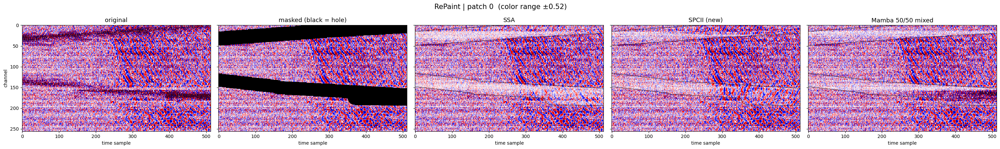

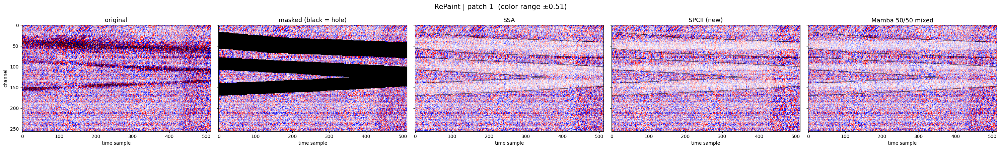

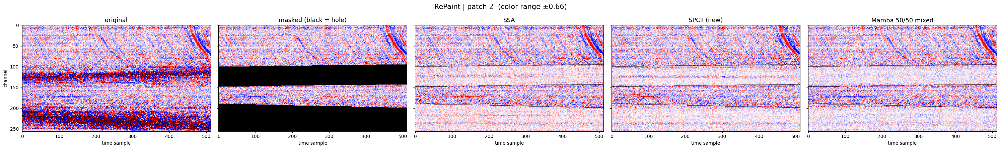

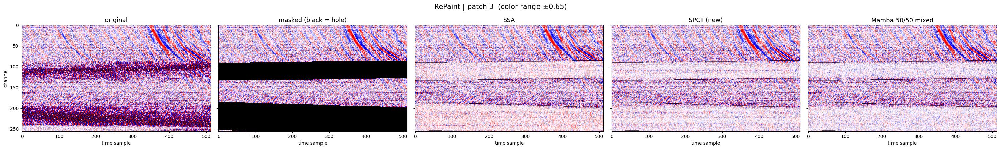

In [11]:
def show_row(k,i,zoom=None,outline=True):
    """k = index in X, i = patch id. zoom = (c0,c1,t0,t1) shows only a section."""
    x=X[k,0].detach().cpu(); m=M[k,0].cpu()
    w=float(torch.quantile(x.abs().flatten(),0.98))
    cmap=plt.get_cmap("seismic").copy(); cmap.set_bad("black")

    masked=x.clone(); masked[m==0]=float("nan")
    panels=[(x,"original"),(masked,"masked (black = hole)")]+[(r[k,0].detach().cpu(),n) for n,r in results.items()]

    fig,axes=plt.subplots(1,len(panels),figsize=(6*len(panels),4.5),sharey=True)
    for j,(a,(img,title)) in enumerate(zip(axes,panels)):
        a.imshow(img,aspect="auto",cmap=cmap,vmin=-w,vmax=w,interpolation="nearest")
        if j>=2 and outline: a.contour(m,levels=[0.5],colors="k",linewidths=0.6)     # hole outline on results
        a.set_title(title,fontsize=13); a.set_xlabel("time sample")
        if zoom: a.set_ylim(zoom[1],zoom[0]); a.set_xlim(zoom[2],zoom[3])
    axes[0].set_ylabel("channel")
    fig.suptitle(f"RePaint | patch {i}  (color range ±{w:.2f})",fontsize=15)
    plt.tight_layout(); plt.show()

for k,i in enumerate(patch_ids):
    show_row(k,i)

In [6]:
test_set_eq=DasDataset([das_data/"test_1001.h5"])
all_eq=torch.stack([test_set_eq[i] for i in range(len(test_set_eq))])
rms_eq=all_eq.pow(2).mean(dim=(1,2,3)).sqrt()
eq_ids=torch.argsort(rms_eq,descending=True)[:4].tolist()     # 4 loud earthquake windows
print("earthquake windows:",eq_ids)

X_eq=all_eq[eq_ids].to(device)
M_eq=M                                                         # same 4 traffic masks as before

earthquake windows: [429, 384, 63, 2]


In [13]:
settings={"U=3, from t=300":dict(jump_n_sample=3,start_resampling=300),
          "U=10, from t=1000":dict(jump_n_sample=10,start_resampling=1000)}

results_eq={}
for sname,s in settings.items():
    for name,model in models:
        torch.manual_seed(0)
        res,_,_=sample_repaint(model,scheduler,X_eq,M_eq,jump_length=10,**s)
        results_eq[(sname,name)]=res
        print(sname,"|",name,"done")

U=3, from t=300 | SSA done
U=3, from t=300 | SPCII (new) done
U=3, from t=300 | Mamba 50/50 mixed done
U=10, from t=1000 | SSA done
U=10, from t=1000 | SPCII (new) done
U=10, from t=1000 | Mamba 50/50 mixed done


In [14]:
hole=(M_eq==0)
for (sname,name),r in results_eq.items():
    ratios=[(r[k][hole[k]].pow(2).mean().sqrt()/X_eq[k][hole[k]].pow(2).mean().sqrt()).item() for k in range(len(eq_ids))]
    print(f"{sname:18s} | {name:18s} | RMS ratio hole: {np.round(ratios,2)} | mean {np.mean(ratios):.2f}")

U=3, from t=300    | SSA                | RMS ratio hole: [0.67 0.54 0.35 0.41] | mean 0.49
U=3, from t=300    | SPCII (new)        | RMS ratio hole: [1.06 1.05 0.82 0.83] | mean 0.94
U=3, from t=300    | Mamba 50/50 mixed  | RMS ratio hole: [1.17 0.75 0.81 0.59] | mean 0.83
U=10, from t=1000  | SSA                | RMS ratio hole: [0.8  0.83 0.39 0.33] | mean 0.59
U=10, from t=1000  | SPCII (new)        | RMS ratio hole: [1.6  1.84 1.79 1.52] | mean 1.69
U=10, from t=1000  | Mamba 50/50 mixed  | RMS ratio hole: [1.49 1.54 1.53 1.3 ] | mean 1.46


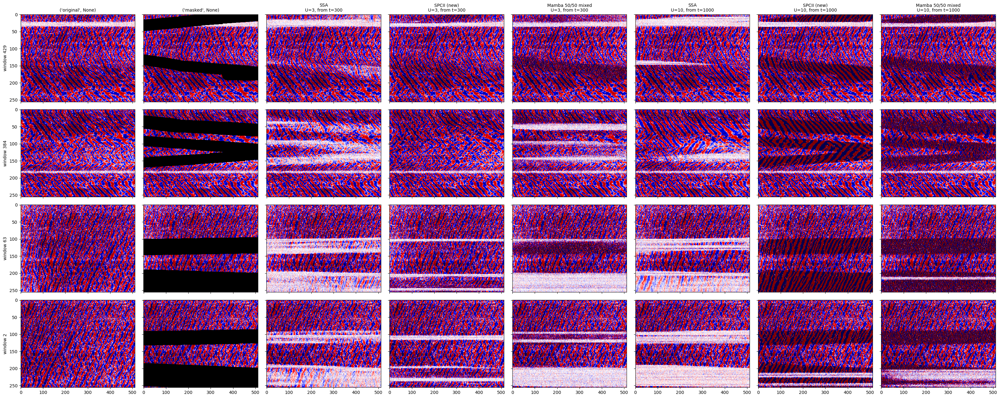

In [15]:
cmap=plt.get_cmap("seismic").copy(); cmap.set_bad("black")
cols=[("original",None),("masked",None)]+list(results_eq.keys())
fig,axes=plt.subplots(len(eq_ids),len(cols),figsize=(4*len(cols),3.2*len(eq_ids)),sharex=True,sharey=True)
for k in range(len(eq_ids)):
    x=X_eq[k,0].cpu(); m=M_eq[k,0].cpu()
    w=float(torch.quantile(x.abs().flatten(),0.98))
    masked=x.clone(); masked[m==0]=float("nan")
    imgs=[x,masked]+[results_eq[c][k,0].cpu() for c in cols[2:]]
    for j,img in enumerate(imgs):
        axes[k,j].imshow(img,aspect="auto",cmap=cmap,vmin=-w,vmax=w,interpolation="nearest")
        if k==0: axes[k,j].set_title(cols[j] if j<2 else f"{cols[j][1]}\n{cols[j][0]}",fontsize=10)
        if j==0: axes[k,j].set_ylabel(f"window {eq_ids[k]}")
plt.tight_layout(); plt.show()

In [8]:
from ddpm.diffusion.repaint_clip import sample_repaint as sample_repaint_clip
results_clip={}
for name,model in models:
    torch.manual_seed(0)
    res,_,_=sample_repaint_clip(model,scheduler,X_eq,M_eq,jump_length=10,
                                jump_n_sample=3,start_resampling=300,clip_x0=1.2)
    results_clip[name]=res
    print(name,"done")

SSA done
SPCII (new) done
Mamba 50/50 mixed done


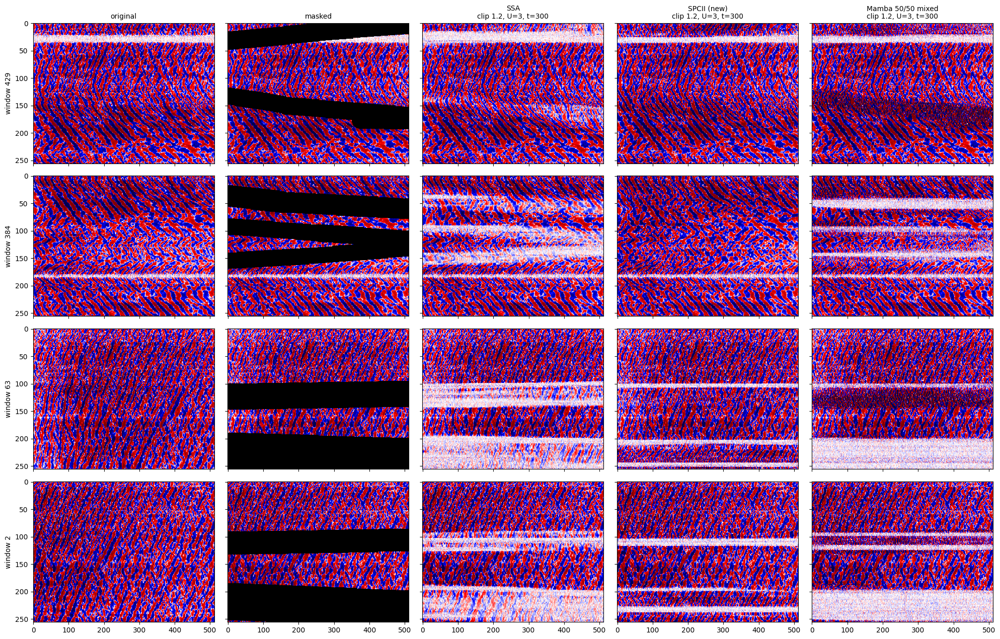

In [9]:
cmap=plt.get_cmap("seismic").copy(); cmap.set_bad("black")
cols=["original","masked"]+[f"{n}\nclip 1.2, U=3, t=300" for n in results_clip.keys()]
fig,axes=plt.subplots(len(eq_ids),len(cols),figsize=(4*len(cols),3.2*len(eq_ids)),sharex=True,sharey=True)
for k in range(len(eq_ids)):
    x=X_eq[k,0].cpu(); m=M_eq[k,0].cpu()
    w=float(torch.quantile(x.abs().flatten(),0.98))
    masked=x.clone(); masked[m==0]=float("nan")
    imgs=[x,masked]+[r[k,0].cpu() for r in results_clip.values()]
    for j,img in enumerate(imgs):
        axes[k,j].imshow(img,aspect="auto",cmap=cmap,vmin=-w,vmax=w,interpolation="nearest")
        if k==0: axes[k,j].set_title(cols[j],fontsize=10)
        if j==0: axes[k,j].set_ylabel(f"window {eq_ids[k]}")
plt.tight_layout(); plt.show()

In [7]:
checkpoints=ckpt_dir if "ckpt_dir" in globals() else Path("checkpoints")
model_mamba_orig=DDPM_MAMBA(**cfg).to(device)
model_mamba_orig.load_state_dict(torch.load(checkpoints/"das_ddpm_earthquake_model_mamba.pth",map_location=device)["model_earthquake_mamba"])
model_mamba_orig.eval()

models_traffic=[("SPCII (new)",model_spcii_old),("Mamba (original)",model_mamba_orig),("Mamba 50/50 mixed",model_mamba)]

In [ ]:
from ddpm.diffusion.repaint_clip import sample_repaint as sample_repaint_clip
results_traffic={}
for name,model in models_traffic:
    torch.manual_seed(0)
    res,_,_=sample_repaint_clip(model,scheduler,X,M,jump_length=10,
                                jump_n_sample=3,start_resampling=300,clip_x0=1.2)
    results_traffic[name]=res
    print(name,"done")

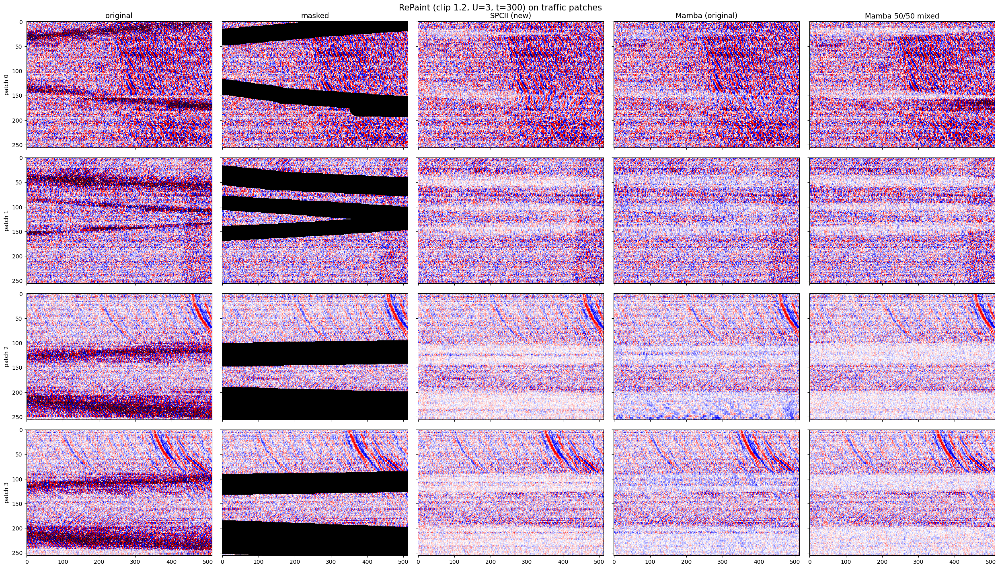

In [14]:
cmap=plt.get_cmap("seismic").copy(); cmap.set_bad("black")
cols=["original","masked"]+list(results_traffic.keys())
fig,axes=plt.subplots(len(patch_ids),len(cols),figsize=(5*len(cols),3.6*len(patch_ids)),sharex=True,sharey=True)
for k,i in enumerate(patch_ids):
    x=X[k,0].cpu(); m=M[k,0].cpu()
    w=float(torch.quantile(x.abs().flatten(),0.98))
    masked=x.clone(); masked[m==0]=float("nan")
    imgs=[x,masked]+[r[k,0].cpu() for r in results_traffic.values()]
    for j,img in enumerate(imgs):
        axes[k,j].imshow(img,aspect="auto",cmap=cmap,vmin=-w,vmax=w,interpolation="nearest")
        if k==0: axes[k,j].set_title(cols[j],fontsize=13)
        if j==0: axes[k,j].set_ylabel(f"patch {i}")
fig.suptitle("RePaint (clip 1.2, U=3, t=300) on traffic patches",fontsize=15)
plt.tight_layout(); plt.show()

In [10]:
from ddpm.diffusion.repaint_clip import sample_repaint as sample_repaint_clip
settings={"clip, U=10, t=300":dict(jump_n_sample=10,start_resampling=300),
          "clip, U=10, t=1000":dict(jump_n_sample=10,start_resampling=1000)}

results_traffic_u10={}
for sname,s in settings.items():
    for name,model in models_traffic:
        torch.manual_seed(0)
        res,_,_=sample_repaint_clip(model,scheduler,X,M,jump_length=10,clip_x0=1.2,**s)
        results_traffic_u10[(sname,name)]=res
        print(sname,"|",name,"done")

clip, U=10, t=300 | SPCII (new) done
clip, U=10, t=300 | Mamba (original) done
clip, U=10, t=300 | Mamba 50/50 mixed done
clip, U=10, t=1000 | SPCII (new) done
clip, U=10, t=1000 | Mamba (original) done
clip, U=10, t=1000 | Mamba 50/50 mixed done


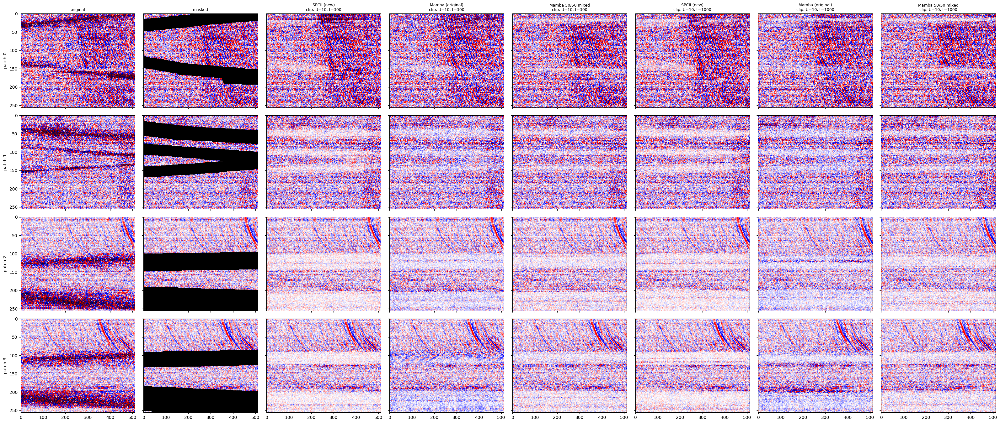

In [11]:
cmap=plt.get_cmap("seismic").copy(); cmap.set_bad("black")
keys=list(results_traffic_u10.keys())
cols=["original","masked"]+[f"{n}\n{s}" for s,n in keys]
fig,axes=plt.subplots(len(patch_ids),len(cols),figsize=(4*len(cols),3.4*len(patch_ids)),sharex=True,sharey=True)
for k,i in enumerate(patch_ids):
    x=X[k,0].cpu(); m=M[k,0].cpu()
    w=float(torch.quantile(x.abs().flatten(),0.98))
    masked=x.clone(); masked[m==0]=float("nan")
    imgs=[x,masked]+[results_traffic_u10[c][k,0].cpu() for c in keys]
    for j,img in enumerate(imgs):
        axes[k,j].imshow(img,aspect="auto",cmap=cmap,vmin=-w,vmax=w,interpolation="nearest")
        if k==0: axes[k,j].set_title(cols[j],fontsize=9)
        if j==0: axes[k,j].set_ylabel(f"patch {i}")
plt.tight_layout(); plt.show()

In [13]:
def center_square_mask(H,W,size,device):
    """1 = keep, 0 = hole. Square hole of size x size pixels in the middle."""
    m=torch.ones(1,H,W,device=device)
    c0,t0=(H-size)//2,(W-size)//2
    m[:,c0:c0+size,t0:t0+size]=0.0
    return m

sizes=[32,64,96]                      # hole edge length in pixels
win=X_eq[:2]                          # two loud earthquake windows
win_ids=eq_ids[:2]

# every window combined with every size -> one batch
X_sq=torch.cat([win[k:k+1] for k in range(len(win)) for _ in sizes])                          # [6,1,256,512]
M_sq=torch.stack([center_square_mask(256,512,s,device) for _ in range(len(win)) for s in sizes])  # [6,1,256,512]
labels=[(win_ids[k],s) for k in range(len(win)) for s in sizes]
print(labels)

[(429, 32), (429, 64), (429, 96), (384, 32), (384, 64), (384, 96)]


In [14]:
models_test=[("SSA",model_ssa),("SPCII (new)",model_spcii_old),("Mamba (original)",model_mamba_orig)]

results_sq={}
for name,model in models_test:
    torch.manual_seed(0)
    res,_,_=sample_repaint_clip(model,scheduler,X_sq,M_sq,jump_length=10,
                                jump_n_sample=3,start_resampling=300,clip_x0=1.2)
    results_sq[name]=res
    print(name,"done")

SSA done
SPCII (new) done
Mamba (original) done


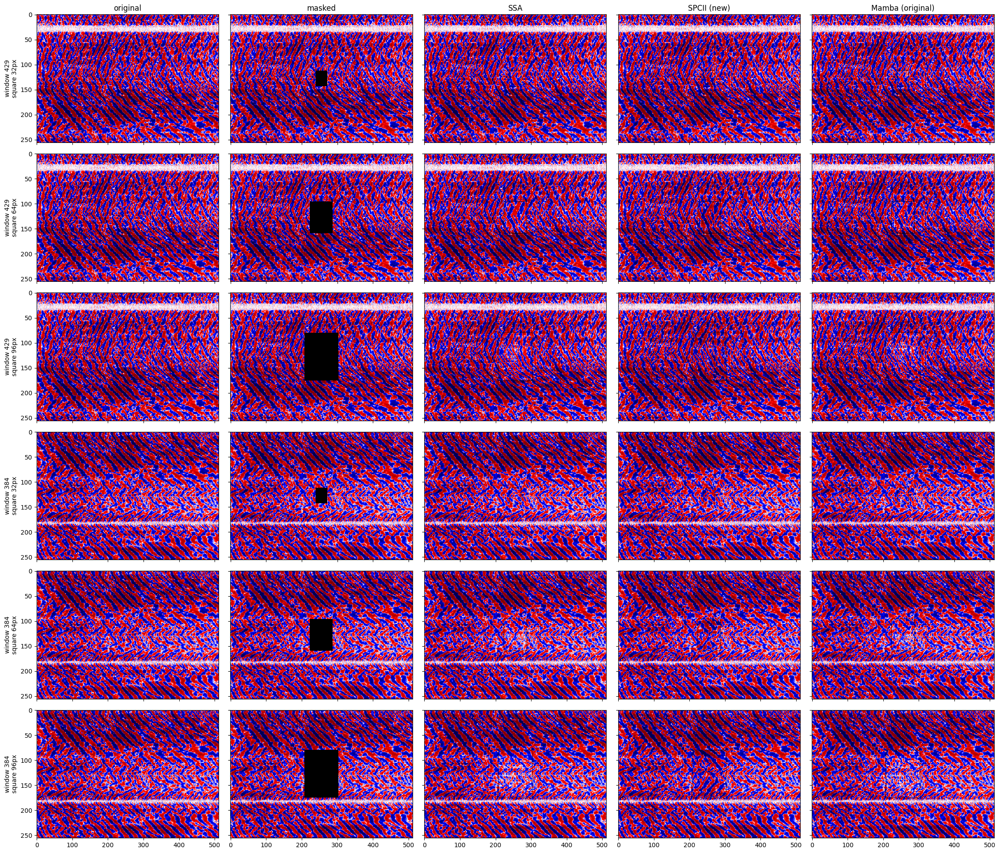

In [15]:
cmap=plt.get_cmap("seismic").copy(); cmap.set_bad("black")
cols=["original","masked"]+list(results_sq.keys())
fig,axes=plt.subplots(len(labels),len(cols),figsize=(4.5*len(cols),3.2*len(labels)),sharex=True,sharey=True)
for j,(wid,s) in enumerate(labels):
    x=X_sq[j,0].cpu(); m=M_sq[j,0].cpu()
    w=float(torch.quantile(x.abs().flatten(),0.98))
    masked=x.clone(); masked[m==0]=float("nan")
    imgs=[x,masked]+[r[j,0].cpu() for r in results_sq.values()]
    for c,img in enumerate(imgs):
        axes[j,c].imshow(img,aspect="auto",cmap=cmap,vmin=-w,vmax=w,interpolation="nearest")
        if c>=2: axes[j,c].contour(m,levels=[0.5],colors="k",linewidths=0.5)
        if j==0: axes[j,c].set_title(cols[c],fontsize=12)
        if c==0: axes[j,c].set_ylabel(f"window {wid}\nsquare {s}px")
plt.tight_layout(); plt.show()

In [16]:
sizes=[96,128,160,192]                 # 192 covers 75% of the channels
win=X_eq[:2]; win_ids=eq_ids[:2]

X_sq=torch.cat([win[k:k+1] for k in range(len(win)) for _ in sizes])
M_sq=torch.stack([center_square_mask(256,512,s,device) for _ in range(len(win)) for s in sizes])
labels=[(win_ids[k],s) for k in range(len(win)) for s in sizes]

In [17]:
models_test=[("SSA",model_ssa),("SPCII (new)",model_spcii_old),("Mamba (original)",model_mamba_orig)]

results_sq={}
for name,model in models_test:
    torch.manual_seed(0)
    res,_,_=sample_repaint_clip(model,scheduler,X_sq,M_sq,jump_length=10,
                                jump_n_sample=3,start_resampling=300,clip_x0=1.2)
    results_sq[name]=res
    print(name,"done")

SSA done
SPCII (new) done
Mamba (original) done


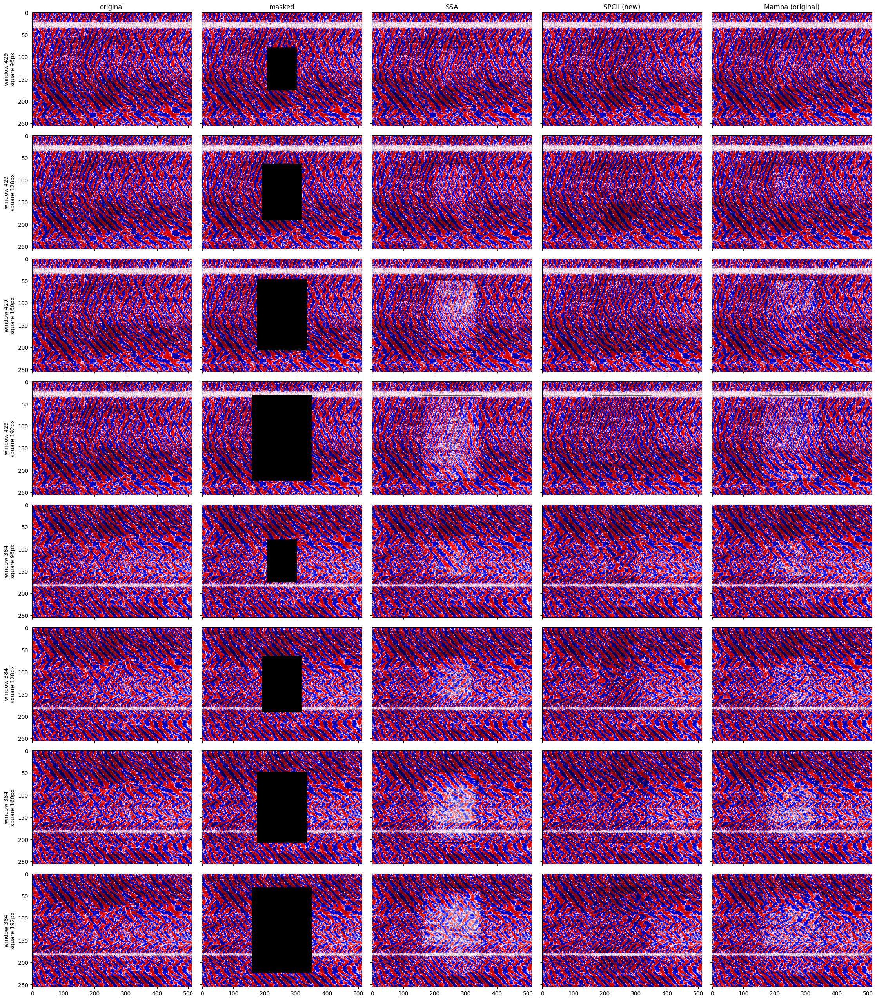

In [18]:
cmap=plt.get_cmap("seismic").copy(); cmap.set_bad("black")
cols=["original","masked"]+list(results_sq.keys())
fig,axes=plt.subplots(len(labels),len(cols),figsize=(4.5*len(cols),3.2*len(labels)),sharex=True,sharey=True)
for j,(wid,s) in enumerate(labels):
    x=X_sq[j,0].cpu(); m=M_sq[j,0].cpu()
    w=float(torch.quantile(x.abs().flatten(),0.98))
    masked=x.clone(); masked[m==0]=float("nan")
    imgs=[x,masked]+[r[j,0].cpu() for r in results_sq.values()]
    for c,img in enumerate(imgs):
        axes[j,c].imshow(img,aspect="auto",cmap=cmap,vmin=-w,vmax=w,interpolation="nearest")
        if c>=2: axes[j,c].contour(m,levels=[0.5],colors="k",linewidths=0.5)
        if j==0: axes[j,c].set_title(cols[c],fontsize=12)
        if c==0: axes[j,c].set_ylabel(f"window {wid}\nsquare {s}px")
plt.tight_layout(); plt.show()

In [21]:
patch_id = 0      # 1111 patch with earthquake + traffic
size     = 128    # side length of the square

x_one = X[patch_id:patch_id+1].to(device)                        # (1,1,256,512)
m_one = torch.stack([center_square_mask(256,512,size,device)])   # 1=keep, 0=hole
x_one_masked = x_one*m_one

In [22]:
from ddpm.diffusion.repaint_clip import sample_repaint

repaint_models = {"SSA": model_ssa, "SPCII": model_spcii_old, "Mamba": model_mamba}

results_one = {}
for name, mdl in repaint_models.items():
    torch.manual_seed(0)
    out,_,_ = sample_repaint(mdl, scheduler, x_one, m_one,
                             jump_length=10, jump_n_sample=3, start_resampling=300, clip_x0=1.2)
    results_one[name] = out.cpu()

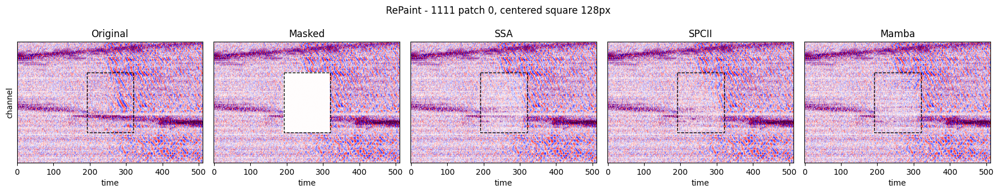

In [23]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

panels = [("Original", x_one.cpu()), ("Masked", x_one_masked.cpu())] + list(results_one.items())
c0, t0 = (256-size)//2, (512-size)//2

fig, axes = plt.subplots(1, len(panels), figsize=(3.5*len(panels), 3.4))
for ax, (title, img) in zip(axes, panels):
    ax.imshow(img[0,0], aspect="auto", cmap="seismic", vmin=-1, vmax=1)
    ax.add_patch(patches.Rectangle((t0,c0), size, size, fill=False, ec="k", lw=1, ls="--"))
    ax.set_title(title); ax.set_xlabel("time"); ax.set_yticks([])
axes[0].set_ylabel("channel")
plt.suptitle(f"RePaint - 1111 patch {patch_id}, centered square {size}px")
plt.tight_layout(); plt.show()